CUSTOMER DATASET
   annual_spend  orders_per_year  site_visits_per_month  discount_usage_pct
0    890.704666               11                     12           66.407412
1    611.798600               10                     18           25.508722
2    575.570142                9                      7           12.703358
3    575.576219                5                     16            5.853660
4   1541.534984                8                      6           30.541350
5   1031.613064                9                      9           15.766103
6    492.785019                4                     15           17.401045
7    913.602425                6                     16           76.075931
8    770.406484                8                     13            1.583807
9    150.914181                5                     10           55.781013

DATASET SUMMARY
       annual_spend  orders_per_year  site_visits_per_month  \
count        600.00           600.00                 600.00   
mean

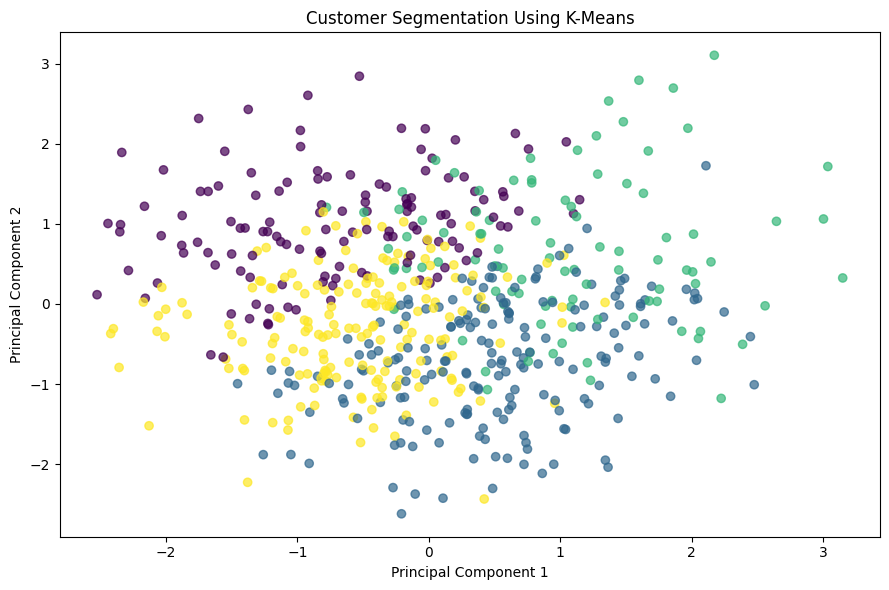

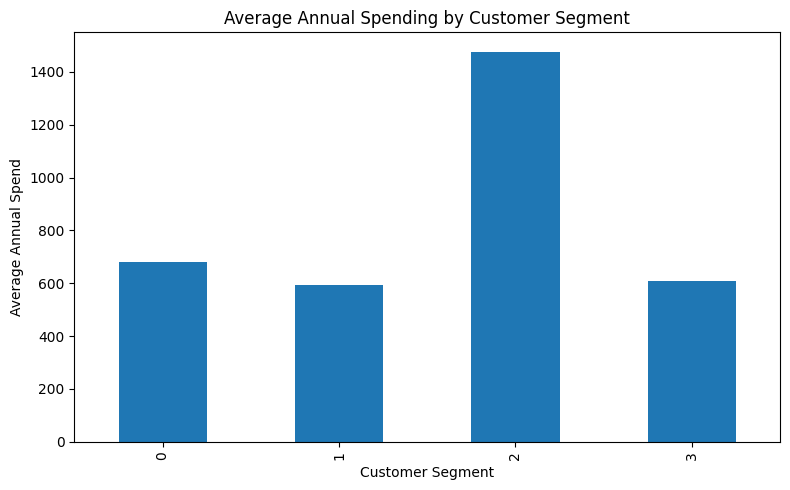


MARKETING RECOMMENDATIONS
         customer_count  average_annual_spend  average_orders  \
segment                                                         
0                   130                681.56            7.83   
1                   192                594.30            8.27   
2                    95               1475.72            8.38   
3                   183                607.76            7.37   

         average_discount_usage                           marketing_strategy  
segment                                                                       
0                         35.73  Personalized recommendations and engagement  
1                         76.99         Targeted discounts and value bundles  
2                         49.80           Loyalty rewards and premium offers  
3                         26.14    Retention campaigns and product discovery  

BUSINESS RECOMMENDATIONS
1. Design campaigns for each behavioral segment.
2. Offer loyalty benefits to valu

In [1]:

# PROJECT 4: AI CUSTOMER SEGMENTATION

# STEP 1: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

np.random.seed(42)


# STEP 2: GENERATE CUSTOMER DATA

n = 600

df = pd.DataFrame({
    "annual_spend": np.random.gamma(3, 250, n),
    "orders_per_year": np.random.poisson(8, n),
    "site_visits_per_month": np.random.poisson(12, n),
    "discount_usage_pct": np.random.uniform(0, 100, n)
})

print("CUSTOMER DATASET")
print(df.head(10))

print("\nDATASET SUMMARY")
print(df.describe().round(2))


# STEP 3: PREPARE THE FEATURES

features = [
    "annual_spend",
    "orders_per_year",
    "site_visits_per_month",
    "discount_usage_pct"
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])


# STEP 4: BUILD THE CUSTOMER SEGMENTATION MODEL

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["segment"] = kmeans.fit_predict(X_scaled)

print("\nCUSTOMER SEGMENT ASSIGNMENTS")
print(df[features + ["segment"]].head(15))


# STEP 5: EVALUATE CLUSTER SEPARATION

score = silhouette_score(X_scaled, df["segment"])

print("\nSILHOUETTE SCORE:", round(score, 3))


# STEP 6: ANALYZE CUSTOMER SEGMENTS

segment_summary = df.groupby("segment").agg(
    customer_count=("segment", "size"),
    average_annual_spend=("annual_spend", "mean"),
    average_orders=("orders_per_year", "mean"),
    average_site_visits=("site_visits_per_month", "mean"),
    average_discount_usage=("discount_usage_pct", "mean")
).round(2)

print("\nCUSTOMER SEGMENT PROFILE")
print(segment_summary)


# STEP 7: VISUALIZE SEGMENTS USING PCA

pca = PCA(n_components=2)
coordinates = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    c=df["segment"],
    alpha=0.7
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()


# STEP 8: COMPARE AVERAGE SPENDING BY SEGMENT

segment_summary["average_annual_spend"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Annual Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Annual Spend")
plt.tight_layout()
plt.show()


# STEP 9: ASSIGN MARKETING STRATEGIES

def recommend_strategy(row):
    if (
        row["average_annual_spend"] > df["annual_spend"].quantile(0.75)
        and row["average_orders"] >= df["orders_per_year"].median()
    ):
        return "Loyalty rewards and premium offers"

    elif row["average_discount_usage"] > 60:
        return "Targeted discounts and value bundles"

    elif row["average_site_visits"] > df["site_visits_per_month"].median():
        return "Personalized recommendations and engagement"

    else:
        return "Retention campaigns and product discovery"


segment_summary["marketing_strategy"] = segment_summary.apply(
    recommend_strategy,
    axis=1
)

print("\nMARKETING RECOMMENDATIONS")
print(segment_summary[
    [
        "customer_count",
        "average_annual_spend",
        "average_orders",
        "average_discount_usage",
        "marketing_strategy"
    ]
])


# STEP 10: BUSINESS INSIGHTS

print("\nBUSINESS RECOMMENDATIONS")
print("1. Design campaigns for each behavioral segment.")
print("2. Offer loyalty benefits to valuable repeat customers.")
print("3. Use discounts selectively for price-sensitive customers.")
print("4. Improve engagement through personalized recommendations.")
print("5. Monitor segment changes over time.")

print("\nPROJECT 4 COMPLETED SUCCESSFULLY")
print("Note: Synthetic data is used for demonstration.")
